In [1]:
# Step 0a: Install dependencies (run once per machine)
# What : Install the libraries used by both notebooks, then comment the line out again.
# Why  : Both notebooks run in the same environment.
# Check: No error is raised once the line is uncommented and run.

# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

In [2]:
# Step 0b: Create folders and helper functions
# What : Create data/raw, data/processed, report and sql; define fetch(), unzip_all() and
#        find1().
# Why  : Both notebooks share one folder layout so that files can be handed over.
# Check: The cell finishes without error.

import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

In [3]:
# Step 1a: Download the raw data
# What : Download sdwpf_245days_v1.csv into data/raw/ and unzip it. The download is skipped
#        if the file already exists.
# Why  : Anyone who reruns the notebook must receive exactly the same dataset.
# Check: The cell prints the path of the file. If the download fails, get the file by hand
#        from doi.org/10.6084/m9.figshare.24798654, copy it to data/raw/ and rerun.

FILES = [('https://ndownloader.figshare.com/files/46005813', 'sdwpf_245days_v1.csv')]
NEED = ['*245days*.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from doi.org/10.6084/m9.figshare.24798654 (file sdwpf_245days_v1.csv) into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

downloading https://ndownloader.figshare.com/files/46005813
*245days*.csv -> data/raw\sdwpf_245days_v1.csv 326469 kB


In [4]:
# Step 1b: Load the raw data into a working table
# What : Read the CSV with DuckDB, build the 10-minute step index and keep the 13 SCADA
#        columns.
# Why  : Every later step uses this table; the row and column counts printed here go into
#        the Data section.
# Check: Compare the counts with the dataset description; if they differ, report the real
#        numbers.

# Dataset: SDWPF (Zhou et al., 2024): SCADA records of 134 wind turbines every 10 minutes for 245 days, about 4.7 million rows, 13 columns
# download (one CSV, 334 MB, no account): https://ndownloader.figshare.com/files/46005813  (sdwpf_245days_v1.csv)
import pandas as pd, numpy as np, glob, duckdb
src = glob.glob('data/raw/**/*245days*.csv', recursive=True)[0]
con = duckdb.connect()
df = con.execute(f"""SELECT TurbID, Day, Tmstamp, (Day - 1) * 144 + CAST(SUBSTR(Tmstamp, 1, 2) AS INT) * 6 + CAST(SUBSTR(Tmstamp, 4, 2) AS INT) / 10 AS step,
                            Wspd, Wdir, Etmp, Itmp, Ndir, Pab1, Pab2, Pab3, Prtv, Patv
                     FROM read_csv_auto('{src}', types={{'Tmstamp': 'VARCHAR'}}) ORDER BY TurbID, step""").df()
df['step'] = df.step.astype(int); print(df.shape, df.TurbID.nunique(), 'turbines', df.Day.max(), 'days'); print(df[['Wspd', 'Patv']].describe().T[['mean', '50%', 'max']])

(4727520, 14) 134 turbines 245 days
            mean     50%      max
Wspd    5.028376    4.34    26.29
Patv  350.445751  179.08  1567.02


In [5]:
# Step 2: Rule-based cleaning with a log
# What : Check value ranges, flag invalid rows with four rules, save the parquet file and
#        the cleaning log.
# Why  : Reviewers will ask why the row count differs from the source; the log is the
#        answer.
# Check: Open report/table_cleaning_log.csv: every flagged or removed row must have a stated
#        reason.

# Note: the validity rules of the data paper are only flagged here, because RQ3 measures what each rule changes
log = [['raw rows', len(df)], ['turbines', df.TurbID.nunique()]]
df['r_missing'] = df.Patv.isna().astype(int)
df['r_negative'] = (df.Patv < 0).astype(int)                                                            # rule 1: negative power is treated as zero
df['r_unknown'] = (((df.Patv <= 0) & (df.Wspd > 2.5)) | (df[['Pab1', 'Pab2', 'Pab3']] > 89).any(axis=1)).astype(int)   # rule 2: stopped or curtailed turbine
df['r_abnormal'] = ((df.Ndir.abs() > 720) | (df.Wdir.abs() > 180)).astype(int)                           # rule 3: impossible angles
for c in ['r_missing', 'r_negative', 'r_unknown', 'r_abnormal']: log.append([c + ' rows', int(df[c].sum())])
df['valid'] = ((df.r_missing == 0) & (df.r_unknown == 0) & (df.r_abnormal == 0)).astype(int); log.append(['rows valid under all rules', int(df.valid.sum())])
df['hour'] = (df.step % 144) / 6
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.drop(columns=['Tmstamp']).to_parquet('data/processed/sdwpf.parquet', index=False); print(df.shape)

[['raw rows', 4727520], ['turbines', 134], ['r_missing rows', 49518], ['r_negative rows', 1263062], ['r_unknown rows', 1082113], ['r_abnormal rows', 127], ['rows valid under all rules', 3595859]]
(4727520, 20)


In [6]:
# Step 2b.1: Load the cleaned table and look at a fixed sample
# What : Define the plotting helpers (bar_chart, nice), read the parquet file, set the
#        target (Patv) and the group column (TurbID), draw a fixed 50,000-row sample.
# Why  : A fixed sample keeps every exploratory plot fast and reproducible.
# Check: The row count matches the cleaning log.

import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/sdwpf.parquet'); TGT, GRP = 'Patv', 'TurbID'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

4727520 rows, 19 columns; 19 numeric columns; target: Patv ; group: TurbID


,TurbID,Day,step,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,Patv,r_missing,r_negative,r_unknown,r_abnormal,valid,hour
0,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0,0,0.000000
1,1,1,1,6.17,-3.99,30.73,41.80,25.92,1.0,1.0,1.0,-0.25,494.66,0,0,0,0,1,0.166667
2,1,1,2,6.27,-2.18,30.60,41.63,20.91,1.0,1.0,1.0,-0.24,509.76,0,0,0,0,1,0.333333
3,1,1,3,6.42,-0.73,30.52,41.52,20.91,1.0,1.0,1.0,-0.26,542.53,0,0,0,0,1,0.500000
4,1,1,4,6.25,0.89,30.49,41.38,20.91,1.0,1.0,1.0,-0.23,509.36,0,0,0,0,1,0.666667


In [7]:
# Step 2b.2: Data dictionary
# What : Data type, missing share, number of distinct values and one example for every
#        column.
# Why  : The table goes straight into the Data section (rows, columns, meaning of columns).
# Check: A column with one value or more than 30% missing values is noted and considered for
#        removal.

dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
TurbID,int64,0.00,134,1.0
Day,int64,0.00,245,1.0
step,int64,0.00,35280,0.0
Wspd,float64,1.05,2371,nan
Wdir,float64,1.05,35044,nan
Etmp,float64,1.05,11204,nan
Itmp,float64,1.05,7670,nan
Ndir,float64,1.05,97851,nan
Pab1,float64,1.05,9309,nan
Pab2,float64,1.05,9337,nan


In [8]:
# Step 2b.3: Descriptive statistics of the numeric columns
# What : Mean, standard deviation, 1/25/50/75/99 percentiles, skewness and share of zeros.
# Why  : Strongly skewed columns need a log transform or tail clipping before plotting or
#        linear models.

num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
TurbID,50000.0,67.592,38.633,1.00,2.000,34.000,68.000,101.000,133.000,134.000,-0.005,0.0
Day,50000.0,122.968,70.620,1.00,3.000,62.000,123.000,184.000,243.000,245.000,-0.002,0.0
step,50000.0,17634.664,10169.302,0.00,371.990,8802.000,17619.000,26398.000,34918.030,35279.000,-0.002,0.0
Wspd,49487.0,5.025,3.388,0.00,0.460,2.250,4.320,7.010,14.811,23.400,0.955,0.3
Wdir,49487.0,0.559,31.287,-176.88,-118.653,-3.870,-0.240,3.480,122.154,174.710,0.171,0.4
Etmp,49487.0,40.879,84.800,-272.81,-7.160,14.020,25.770,32.725,394.040,394.330,3.539,0.0
Itmp,49487.0,27.420,18.201,-272.81,1.460,20.100,30.130,36.860,48.740,61.840,-9.518,0.0
Ndir,49487.0,188.951,164.168,-884.83,-217.590,61.145,195.400,323.100,522.234,700.400,-0.331,0.0
Pab1,49487.0,26.867,38.853,-1.99,-1.480,0.010,0.570,83.990,90.390,90.990,0.923,0.3
Pab2,49487.0,26.859,38.850,-2.00,-1.480,0.010,0.570,83.980,90.390,90.960,0.923,0.3


duplicated rows: 0 of 50000 sampled rows


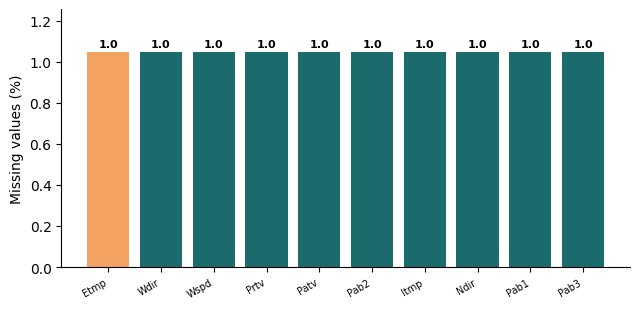

In [9]:
# Step 2b.4: Missing values and duplicate rows
# What : Plot the missing share of the columns that have missing values and count duplicate
#        rows.
# Check: Every column that still has missing values has a treatment recorded in the cleaning
#        log.

miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

{'count': 49487.0, 'mean': 350.278, 'std': 425.199, 'min': -8.35, '5%': -0.3, '50%': 178.39, '95%': 1312.817, 'max': 1559.61}


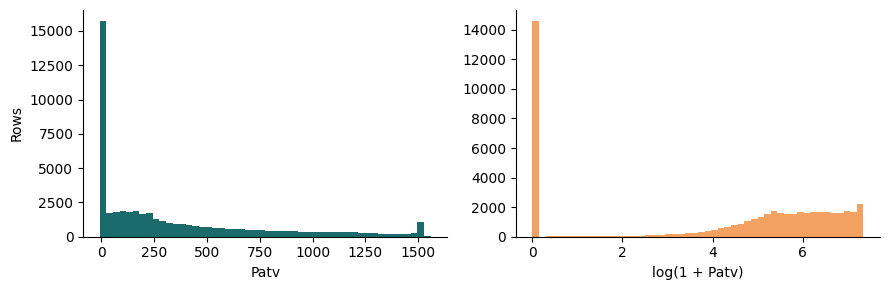

In [10]:
# Step 2b.5: Distribution of the target
# What : Histogram of the target, plus a log scale for a continuous target (class shares for
#        a label).
# Why  : Rare classes need PR-AUC instead of accuracy; a skewed target needs a relative
#        error as well.

fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

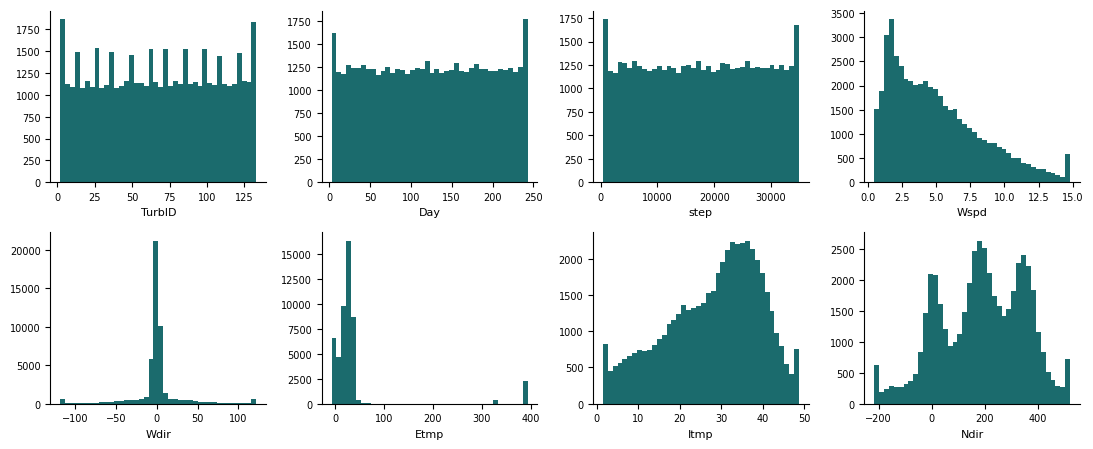

In [11]:
# Step 2b.6: Distributions of the main numeric columns
# What : Eight histograms, clipped at the 1% and 99% percentiles so the main body is
#        visible.
# Check: A column with two peaks usually reflects two operating regimes and should be
#        analysed separately.

cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#1B6B6D'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

In [12]:
# Step 2b.7: Outliers
# What : Share of rows outside 1.5 x IQR for every numeric column.
# Why  : Measurement errors are removed and logged; real events (load peaks, faults) are
#        kept and reported.

N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
valid,23.97
r_unknown,22.94
Wdir,20.37
Prtv,19.46
Etmp,5.83
Patv,4.04
Wspd,1.39
r_missing,1.03
Ndir,0.32
Itmp,0.27


c:\Users\NHAT KHOA\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,0
Wspd,0.852
r_negative,-0.774
r_unknown,-0.666
valid,0.666
Pab1,-0.520
Pab2,-0.518
Pab3,-0.518
Itmp,0.109
Day,-0.064
step,-0.064


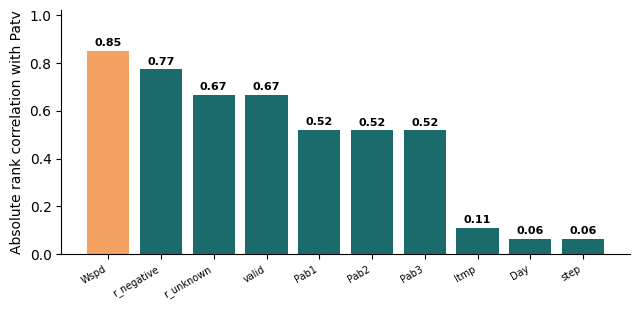

In [13]:
# Step 2b.8: Which columns relate to the target
# What : Spearman rank correlation between each numeric column and the target; plot the ten
#        strongest.
# Why  : An early signal of important features; a correlation close to 1 may be leakage and
#        needs a meaning check.

others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

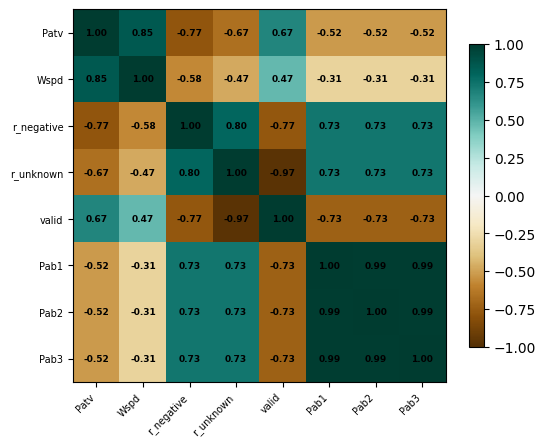

In [14]:
# Step 2b.9: Do the strong columns carry the same information
# What : Correlation matrix of the target and the seven strongest columns.
# Check: If two columns correlate above 0.95 with each other, keep only one when explaining
#        results.

top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

,rows,mean,median,std
TurbID,,,,
1,35280,462.485,233.500,525.820
2,35280,399.944,200.655,468.459
3,35280,415.609,224.135,471.868
4,35280,406.260,215.500,466.953
5,35280,410.838,230.470,462.586
6,35280,423.315,227.390,478.939
7,35280,403.858,215.775,464.872
8,35280,396.917,197.440,471.138
9,35280,409.425,214.580,476.023


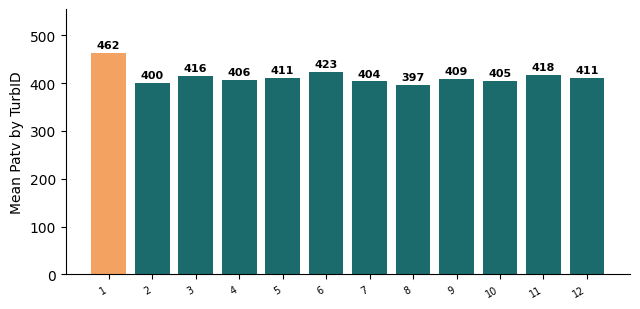

In [15]:
# Step 2b.10: Target by group (turbine)
# What : Row count, mean, median and standard deviation of the target per turbine, with a
#        chart.
# Why  : Differences between turbines hint at RQ1 and at how to split the data in Notebook
#        B.

g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

In [16]:
# Step 3a: Write all SQL queries to sql/queries.sql
# What : Store every query in one SQL script: view over the parquet file, Q1-Q3 for RQ1, Q4
#        for the model table.
# Why  : RQ1 is answered with result tables; the feat table is the input of Notebook B.
# Check: Recompute a small group by hand and compare it with the query result.

SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE wt AS SELECT * FROM 'data/processed/sdwpf.parquet';
-- Q1: share of rows touched by each validity rule
SELECT COUNT(*) AS n, 100.0 * AVG(r_missing) AS missing_pct, 100.0 * AVG(r_negative) AS negative_pct, 100.0 * AVG(r_unknown) AS unknown_pct,
       100.0 * AVG(r_abnormal) AS abnormal_pct, 100.0 * AVG(valid) AS valid_pct FROM wt;
-- Q2: power curve: mean power by wind speed for valid rows and for rows marked unknown
SELECT CAST(FLOOR(Wspd) AS INT) AS wind_ms, COUNT(*) AS n, AVG(CASE WHEN valid = 1 THEN Patv END) AS power_valid_kw, AVG(CASE WHEN r_unknown = 1 THEN Patv END) AS power_unknown_kw
FROM wt WHERE Wspd IS NOT NULL AND Wspd < 20 GROUP BY 1 ORDER BY 1;
-- Q3: turbines ranked by the share of unknown rows
SELECT TurbID, 100.0 * AVG(r_unknown) AS unknown_pct, AVG(CASE WHEN valid = 1 THEN Patv END) AS mean_power_kw, RANK() OVER (ORDER BY AVG(r_unknown) DESC) AS rank
FROM wt GROUP BY 1 ORDER BY 4 LIMIT 10;
-- Q4: model table: 47 turbines chosen by a fixed rule; the feature table itself is built in Python because it depends on the cleaning rules
CREATE OR REPLACE TABLE feat AS SELECT * FROM wt WHERE TurbID % 10 IN (1, 4, 7) OR TurbID % 20 = 0 ORDER BY TurbID, step;
SELECT COUNT(*) AS n, COUNT(DISTINCT TurbID) AS turbines FROM feat;
"""
open('sql/queries.sql', 'w').write(SQL)

1308

In [17]:
# Step 3b: Helper that runs one SQL statement
# What : run() executes one statement; a SELECT result is shown, saved to
#        report/table_q<N>.csv and plotted when it is small.
# Check: The helper is defined without error.

import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

In [18]:
# Step 3c: Create the wt table
# What : Run the first statement of sql/queries.sql: a table over
#        data/processed/sdwpf.parquet.
# Check: The statement prints 'done'.

r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE wt AS SELECT * FROM 'data/processed/sdwpf.parquet';""")

done


In [19]:
# Step 3d - Q1: Share of rows touched by each validity rule
# What : Run the query, read the table and the chart.
# Check: The numbers agree with the cleaning log and the figures of Step 2b.

r = run(r"""-- Q1: share of rows touched by each validity rule
SELECT COUNT(*) AS n, 100.0 * AVG(r_missing) AS missing_pct, 100.0 * AVG(r_negative) AS negative_pct, 100.0 * AVG(r_unknown) AS unknown_pct,
       100.0 * AVG(r_abnormal) AS abnormal_pct, 100.0 * AVG(valid) AS valid_pct FROM wt;""")

,n,missing_pct,negative_pct,unknown_pct,abnormal_pct,valid_pct
0,4727520,1.047441,26.717222,22.889655,0.002686,76.062269


,wind_ms,n,power_valid_kw,power_unknown_kw
0,0,225626,2.661231,-0.278687
1,1,779244,8.969511,-0.278488
2,2,610507,57.003691,-0.293249
3,3,540010,136.951737,-0.296801
4,4,520105,240.625879,-0.257967
5,5,458703,381.368864,-0.252038
6,6,368765,556.025529,-0.247322
7,7,292704,750.589597,-0.251569
8,8,236154,933.940730,-0.259532
9,9,188592,1071.408848,-0.262992


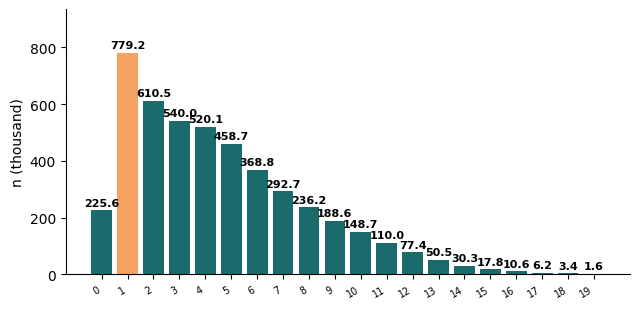

In [20]:
# Step 3e - Q2: Power curve (mean power by wind speed)
# What : Compare valid rows with rows marked unknown, by 1 m/s wind-speed bins.
# Check: The numbers agree with the figures of Step 2b.

r = run(r"""-- Q2: power curve: mean power by wind speed for valid rows and for rows marked unknown
SELECT CAST(FLOOR(Wspd) AS INT) AS wind_ms, COUNT(*) AS n, AVG(CASE WHEN valid = 1 THEN Patv END) AS power_valid_kw, AVG(CASE WHEN r_unknown = 1 THEN Patv END) AS power_unknown_kw
FROM wt WHERE Wspd IS NOT NULL AND Wspd < 20 GROUP BY 1 ORDER BY 1;""")

,TurbID,unknown_pct,mean_power_kw,rank
0,80,30.972222,454.278414,1
1,117,30.053855,430.933388,2
2,122,30.022676,424.863953,3
3,44,29.722222,527.230621,4
4,60,29.373583,467.339015,5
5,123,29.314059,475.517045,6
6,83,28.628118,505.826021,7
7,22,28.370181,543.300499,8
8,82,28.353175,449.288557,9
9,36,28.299320,506.838057,10


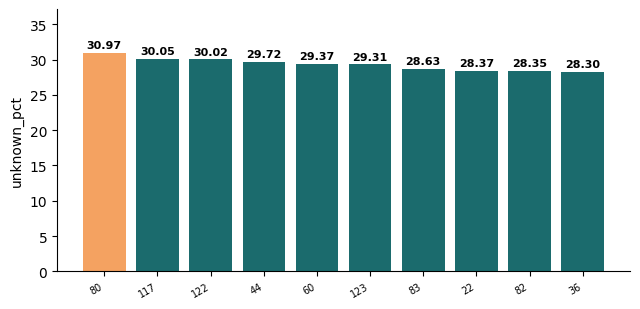

In [21]:
# Step 3f - Q3: Turbines ranked by the share of unknown rows
# What : Rank turbines with a RANK() window function.
# Check: The numbers agree with the figures of Step 2b.

r = run(r"""-- Q3: turbines ranked by the share of unknown rows
SELECT TurbID, 100.0 * AVG(r_unknown) AS unknown_pct, AVG(CASE WHEN valid = 1 THEN Patv END) AS mean_power_kw, RANK() OVER (ORDER BY AVG(r_unknown) DESC) AS rank
FROM wt GROUP BY 1 ORDER BY 4 LIMIT 10;""")

In [22]:
# Step 3g - Q4: Model table
# What : Create the feat table with 47 turbines chosen by a fixed rule (TurbID % 10 in 1, 4,
#        7 or TurbID % 20 = 0). The feature table itself is built in Python in Notebook B
#        because it depends on the cleaning rules.
# Check: The next cell shows the row and turbine counts.

r = run(r"""-- Q4: model table: 47 turbines chosen by a fixed rule; the feature table itself is built in Python because it depends on the cleaning rules
CREATE OR REPLACE TABLE feat AS SELECT * FROM wt WHERE TurbID % 10 IN (1, 4, 7) OR TurbID % 20 = 0 ORDER BY TurbID, step;""")

done


In [23]:
# Step 3h: Size of the model table
# What : Count rows and distinct turbines in feat.
# Check: 47 turbines are returned.

r = run(r"""SELECT COUNT(*) AS n, COUNT(DISTINCT TurbID) AS turbines FROM feat;""")

,n,turbines
0,1658160,47


,column_name,column_type,min,max,approx_unique,null_percentage
0,TurbID,BIGINT,1,134,131,0.00
1,Day,BIGINT,1,245,260,0.00
2,step,BIGINT,0,35279,33339,0.00
3,Wspd,DOUBLE,0.0,26.29,2228,1.05
4,Wdir,DOUBLE,-3030.46,2266.95,35977,1.05
5,Etmp,DOUBLE,-273.03,394.33,9839,1.05
6,Itmp,DOUBLE,-273.17,324.21,7176,1.05
7,Ndir,DOUBLE,-884.86,700.62,97972,1.05
8,Pab1,DOUBLE,-10.0,99.98,7418,1.05
9,Pab2,DOUBLE,-10.0,99.98,7418,1.05


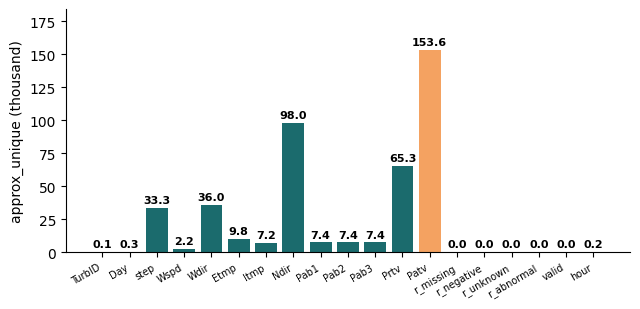

In [24]:
# Step 3i - Extra query 1: Profile of the working table
# What : SUMMARIZE returns min, max, distinct values and missing share of every column in
#        one SQL command.
# Check: Compare with the descriptive statistics of Step 2b.3.

r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE wt)''')

In [25]:
# Step 3j - Extra query 2: Quantiles of the target
# What : The 5%, 25%, 50%, 75%, 95% and 99% quantiles of Patv.
# Why  : They are used to choose thresholds, axis scales and tail clipping for plots.

r = run('''SELECT COUNT(*) AS n, MIN("Patv") AS min, QUANTILE_CONT("Patv", 0.05) AS p05, QUANTILE_CONT("Patv", 0.25) AS p25, MEDIAN("Patv") AS p50, QUANTILE_CONT("Patv", 0.75) AS p75, QUANTILE_CONT("Patv", 0.95) AS p95, QUANTILE_CONT("Patv", 0.99) AS p99, MAX("Patv") AS max FROM wt''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,4727520,-9.33,-0.3,-0.3,179.08,547.66,1316.64,1518.91,1567.02


,grp,mean_target,n,pct_of_rows,rank_by_mean
0,1,462.485064,35280,0.746269,1
1,6,423.315055,35280,0.746269,2
2,11,417.797578,35280,0.746269,3
3,3,415.609248,35280,0.746269,4
4,5,410.837692,35280,0.746269,5
5,12,410.634870,35280,0.746269,6
6,9,409.424730,35280,0.746269,7
7,4,406.259567,35280,0.746269,8
8,70,406.231562,35280,0.746269,9
9,10,405.239000,35280,0.746269,10


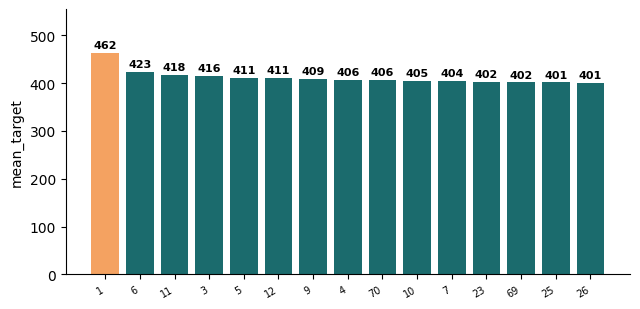

In [26]:
# Step 3k - Extra query 3: Ranking of the groups
# What : Rows and mean target per turbine, ranked with RANK(), plus each turbine's share of
#        all rows.
# Why  : The largest and the most extreme groups are good examples for the Results section.

r = run('''SELECT CAST("TurbID" AS VARCHAR) AS grp, AVG("Patv") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("Patv") DESC) AS rank_by_mean FROM wt GROUP BY 1 ORDER BY 5 LIMIT 15''')

,column_name,column_type,null_percentage,approx_unique
0,Etmp,DOUBLE,0.97,7805
1,Wdir,DOUBLE,0.97,32456
2,Pab1,DOUBLE,0.97,7346
3,Prtv,DOUBLE,0.97,60813
4,Patv,DOUBLE,0.97,142740
5,Pab2,DOUBLE,0.97,7418
6,Itmp,DOUBLE,0.97,5851
7,Ndir,DOUBLE,0.97,95463
8,Pab3,DOUBLE,0.97,7346
9,Wspd,DOUBLE,0.97,2119


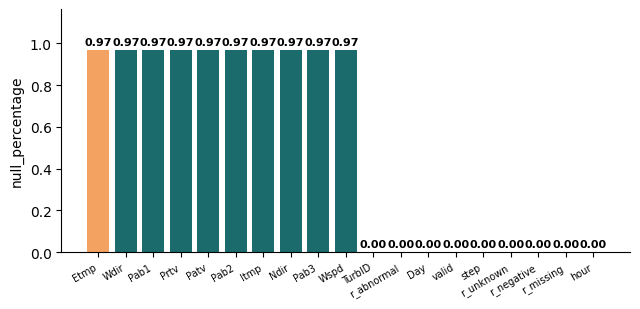

In [27]:
# Step 3l - Extra query 4: Is the model table clean
# What : Data type, missing share and distinct values of every column of feat.
# Check: Any feature column with missing values must be handled before Notebook B.

r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

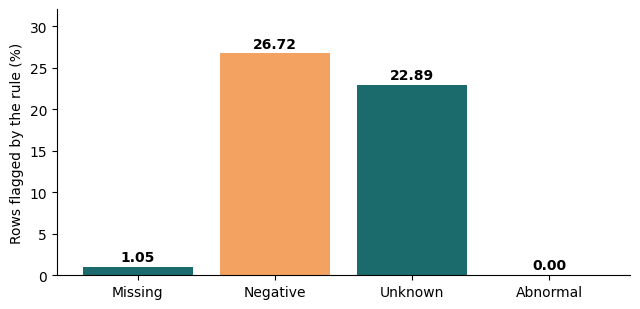

In [28]:
# Step 5: Figure for RQ1
# What : Draw one bar chart from the SQL result with the shared bar_chart() function.
# Why  : A reader should see the RQ1 conclusion within seconds.
# Check: English labels, no top and right spines, bold numbers on the bars, no text over
#        bars. The caption states the conclusion.

import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT 'Missing' AS g, 100.0 * AVG(r_missing) AS v FROM wt UNION ALL SELECT 'Negative', 100.0 * AVG(r_negative) FROM wt UNION ALL SELECT 'Unknown', 100.0 * AVG(r_unknown) FROM wt UNION ALL SELECT 'Abnormal', 100.0 * AVG(r_abnormal) FROM wt""").df()
bar_chart(fig1.g, fig1.v, 'Rows flagged by the rule (%)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

In [29]:
# Hand-over and test cases
# What : Write data/processed/manifest.json (rows, columns, md5 hash) and run the automatic
#        checks.
# Why  : Notebook B reads the manifest first, so the two notebooks cannot drift apart.
# Check: All asserts pass and 'Notebook A: all checks passed' is printed.

import json, hashlib
path = 'data/processed/sdwpf.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/sdwpf.parquet', 'rows': 4727520, 'columns': 19, 'feat_rows': 1658160, 'md5': 'f686f0675f6acbb22622d0c592810e99'}
Notebook A: all checks passed
